# What the model's terms actually look like

The fitted coefficients assume things about their inputs. This notebook looks at the inputs.

Three questions:

1. **Are the burdens normally distributed?** They are z-scored, which centres and scales them — it does
   **not** make them normal. If a burden has a long tail, a handful of founders carry a lot of the
   leverage behind its coefficient.
2. **How do the burdens relate pairwise?** We know they correlate 0.83–0.97. Whether that relationship is
   *linear* is a separate question, and a curved one would mean the linear model is mis-specified.
3. **How do the fitted per-garden effects behave** — against each other, and against garden temperature?

Then two specification checks that grew out of those answers: whether the very different **numbers of
events** per context bias the coefficients (§4), and whether the missing **`bio1c` main effect** matters
(§5).

⚠ **One trap, handled explicitly in §3.** Each garden's total effect is `fixed_part + slope_blup`, and
`fixed_part` is by construction a straight line in `bio1c`. Correlating two contexts' *totals* therefore
mostly correlates two straight lines in the same variable, and will look impressive whatever is true. The
pairwise panels below use the **BLUP deviations** — the part genuinely free to vary per garden. The
vs-temperature panels use the totals, because there the line is exactly what is being asked about.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
SUF="_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall"
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
CC={"CDS":"#2F4A1F","UTR":"#4E6B3A","intron":"#7E9B6B","TE":"#C46A10",
    "promoter":"#5B7A99","intergenic":"#B9B9B9"}
CO=pd.read_csv(f"{PA}/coef_M2p_reml{SUF}.csv").set_index("term")
GD=pd.read_csv(f"{PA}/garden_M2p_reml{SUF}.csv")
SC=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_all6.csv").set_index("context")
PVv={f"sv_{c}":100/(SC.loc[c,"sd_rate"]*SC.loc[c,"med_called"]) for c in SC.index}
B=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str})
L=pd.read_csv(f"{G}/onestage_all/long.csv",dtype={"founder":str})
TECH=L.drop_duplicates("founder").set_index("founder").cactus
FIT=L.groupby("founder").y.mean()          # founder-mean fitness over the 31 gardens
car={c:(B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"]).astype(float) for c in CTX}
cal={c:(B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"]).astype(float) for c in CTX}
RAW={c:(car[c]/cal[c]).to_numpy() for c in CTX}                    # the carried/called rate
zz=lambda v:(v-v.mean())/v.std(ddof=1)
Z={c:zz(RAW[c]) for c in CTX}                                      # exactly what the model fits
CARR={c:car[c].to_numpy() for c in CTX}
print(f"{len(B):,} founders, {len(CTX)} burdens")
print("the model fits the z-scored rate; z-scoring centres and scales, it does not normalise")


231 founders, 6 burdens
the model fits the z-scored rate; z-scoring centres and scales, it does not normalise


## 1 · How is each burden distributed?

Each panel is one burden as the model sees it — the z-scored `carried / called` rate across the 231
founders. The dashed curve is the normal with the same mean and SD, so departures are visible directly.
The annotation gives skew, excess kurtosis, and a Shapiro–Wilk test of normality.

The second row is the same burdens as **raw carried counts**, which is what a biologist would picture, and
is on a very different scale per context.

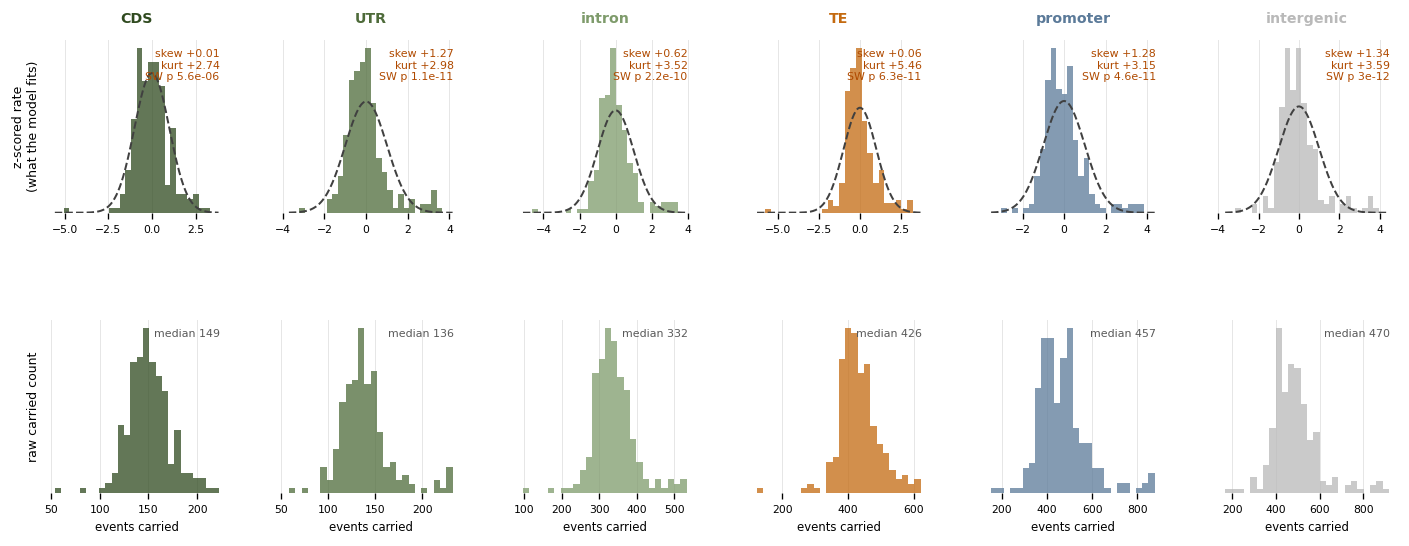

DISTRIBUTION OF EACH BURDEN ACROSS THE 231 FOUNDERS

   context   skew excess kurtosis Shapiro-Wilk p normal at 0.05 min z max z  |z|>3 median carried
       CDS +0.014          +2.744       5.61e-06             no -5.06 +3.32      2            149
       UTR +1.265          +2.977       1.06e-11             no -3.21 +3.65      8            136
    intron +0.619          +3.519       2.21e-10             no -4.64 +3.44      6            332
        TE +0.058          +5.464       6.29e-11             no -5.79 +3.21      5            426
  promoter +1.281          +3.145       4.63e-11             no -3.02 +3.87      7            457
intergenic +1.344          +3.593       3.04e-12             no -3.15 +3.95      7            470

  Skew > 0 means a right tail: a few founders carry far more than the rest. Those founders
  have the most leverage on that burden's coefficient -- which is what the jackknife and
  delete-d sections of sv_burden_model.ipynb test directly.


In [3]:

fig,axs=plt.subplots(2,len(CTX),figsize=(2.42*len(CTX),4.9),
                     gridspec_kw=dict(hspace=0.62,wspace=0.30))
for j,c in enumerate(CTX):
    a=axs[0,j]; style(a,axis="both")
    v=Z[c]
    a.hist(v,bins=26,density=True,color=CC[c],alpha=0.75,lw=0)
    xs=np.linspace(v.min()-0.5,v.max()+0.5,200)
    a.plot(xs,stats.norm.pdf(xs,v.mean(),v.std(ddof=1)),color="0.25",lw=1.2,ls="--")
    sk=stats.skew(v); ku=stats.kurtosis(v); W,pw=stats.shapiro(v)
    a.annotate(f"skew {sk:+.2f}\nkurt {ku:+.2f}\nSW p {pw:.2g}",xy=(0.96,0.95),
               xycoords="axes fraction",ha="right",va="top",fontsize=6.6,
               color="#B04A00" if pw<0.05 else "0.35")
    a.annotate(c,xy=(0.5,1.10),xycoords="axes fraction",ha="center",fontsize=8.5,
               color=CC[c],fontweight="bold")
    a.set_yticks([]); a.tick_params(labelsize=6.5)
    if j==0: a.set_ylabel("z-scored rate\n(what the model fits)",fontsize=7.5)
    a=axs[1,j]; style(a,axis="both")
    a.hist(CARR[c],bins=26,color=CC[c],alpha=0.75,lw=0)
    a.annotate(f"median {np.median(CARR[c]):,.0f}",xy=(0.96,0.95),xycoords="axes fraction",
               ha="right",va="top",fontsize=6.6,color="0.35")
    a.set_yticks([]); a.tick_params(labelsize=6.5)
    a.set_xlabel("events carried",fontsize=7)
    if j==0: a.set_ylabel("raw carried count",fontsize=7.5)
save(fig,"diag_burden_distributions",nb=True); plt.show()
print("DISTRIBUTION OF EACH BURDEN ACROSS THE 231 FOUNDERS\n")
rows=[]
for c in CTX:
    v=Z[c]; W,pw=stats.shapiro(v)
    rows.append({"context":c,"skew":f"{stats.skew(v):+.3f}","excess kurtosis":f"{stats.kurtosis(v):+.3f}",
                 "Shapiro-Wilk p":f"{pw:.3g}","normal at 0.05":"no" if pw<0.05 else "yes",
                 "min z":f"{v.min():+.2f}","max z":f"{v.max():+.2f}",
                 "|z|>3":int((np.abs(v)>3).sum()),
                 "median carried":f"{np.median(CARR[c]):,.0f}"})
print(pd.DataFrame(rows).to_string(index=False))
print("\n  Skew > 0 means a right tail: a few founders carry far more than the rest. Those founders")
print("  have the most leverage on that burden's coefficient -- which is what the jackknife and")
print("  delete-d sections of sv_burden_model.ipynb test directly.")


## 2 · How do the burdens relate to each other?

Lower triangle: every pair of burdens, z-scored, with the fitted line. Upper triangle: the correlation.
Diagonal: the burden against itself as a reference.

The question is not *whether* they correlate — we know they do — but whether the relationship is
**linear**. A curved cloud would mean the model's additive, linear form is wrong, and no amount of
re-parameterising would fix it.

Points are **coloured by founder mean fitness** across the 31 gardens, and the **symbol** marks sequencing
technology (circle = short-read, triangle = cactus assembly). So the clouds can be read two ways at once:
whether high- and low-fitness founders sit in different parts of the burden space, and whether the two
technology panels occupy the same region.

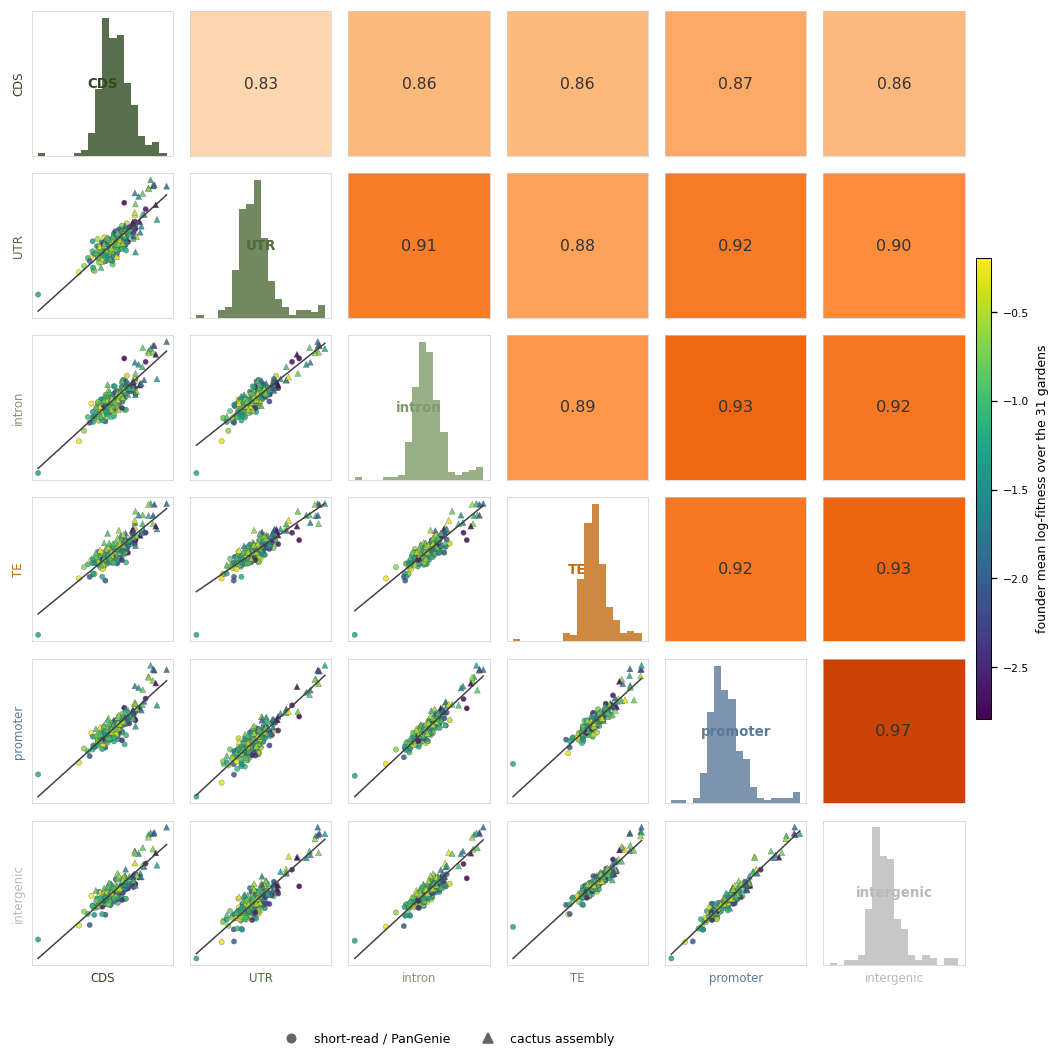

PAIRWISE BURDEN CORRELATIONS (z-scored rate, 231 founders)

              CDS    UTR  intron     TE  promoter  intergenic
CDS         1.000  0.831   0.861  0.861     0.874       0.860
UTR         0.831  1.000   0.913  0.881     0.916       0.901
intron      0.861  0.913   1.000  0.891     0.932       0.918
TE          0.861  0.881   0.891  1.000     0.917       0.933
promoter    0.874  0.916   0.932  0.917     1.000       0.968
intergenic  0.860  0.901   0.918  0.933     0.968       1.000


IS ANY PAIR NONLINEAR?  (Spearman vs Pearson -- a gap means curvature or outlier leverage)

             pair Pearson Spearman difference
UTR vs intergenic  +0.901   +0.797     -0.104
  UTR vs promoter  +0.916   +0.830     -0.086
    UTR vs intron  +0.913   +0.832     -0.082
        UTR vs TE  +0.881   +0.807     -0.074
    CDS vs intron  +0.861   +0.791     -0.071
     intron vs TE  +0.891   +0.823     -0.068
        CDS vs TE  +0.861   +0.804     -0.057
       CDS vs UTR  +0.831   +0.776     -0.05

In [4]:

n=len(CTX); tc=TECH.loc[B.founder].to_numpy(float)
fv=FIT.loc[B.founder].to_numpy(float)                       # founder-mean fitness
FN=mpl.colors.Normalize(np.percentile(fv,2),np.percentile(fv,98))
FCM=plt.get_cmap("viridis")
fig,axs=plt.subplots(n,n,figsize=(1.72*n,1.72*n),gridspec_kw=dict(hspace=0.12,wspace=0.12))
for i in range(n):
    for j in range(n):
        a=axs[i,j]; a.set_xticks([]); a.set_yticks([])
        for sp in a.spines.values(): sp.set_linewidth(0.4); sp.set_color("0.8")
        ci,cj=CTX[i],CTX[j]
        if i==j:
            a.hist(Z[ci],bins=18,color=CC[ci],alpha=0.8,lw=0)
            a.annotate(ci,xy=(0.5,0.5),xycoords="axes fraction",ha="center",va="center",
                       fontsize=8,color=CC[ci],fontweight="bold")
        elif i>j:
            # colour = founder fitness, symbol = sequencing technology
            for msk,mk,sz in ((tc==0,"o",10),(tc==1,"^",13)):
                a.scatter(Z[cj][msk],Z[ci][msk],s=sz,c=fv[msk],cmap=FCM,norm=FN,
                          marker=mk,linewidth=0.2,edgecolor="0.3",alpha=0.85)
            m,b0=np.polyfit(Z[cj],Z[ci],1); xs=np.array([Z[cj].min(),Z[cj].max()])
            a.plot(xs,m*xs+b0,color="0.25",lw=0.9)
        else:
            r=np.corrcoef(Z[ci],Z[cj])[0,1]
            a.annotate(f"{r:.2f}",xy=(0.5,0.5),xycoords="axes fraction",ha="center",va="center",
                       fontsize=9+6*(r-0.8),color="0.2")
            a.set_facecolor(plt.get_cmap("Oranges")((r-0.78)/0.24))
        if j==0: a.set_ylabel(ci,fontsize=7,color=CC[ci])
        if i==n-1: a.set_xlabel(cj,fontsize=7,color=CC[cj])
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=FN,cmap=FCM),ax=axs,pad=0.012,fraction=0.016,aspect=30)
cb.set_label("founder mean log-fitness over the 31 gardens",fontsize=7.5); cb.ax.tick_params(labelsize=6.5)
fig.legend([plt.Line2D([],[],marker="o",ls="none",color="0.4",ms=5),
            plt.Line2D([],[],marker="^",ls="none",color="0.4",ms=6)],
           ["short-read / PanGenie","cactus assembly"],frameon=False,fontsize=7.5,
           loc="upper center",bbox_to_anchor=(0.46,0.065),ncol=2)
save(fig,"diag_burden_pairs",nb=True); plt.show()
print("PAIRWISE BURDEN CORRELATIONS (z-scored rate, 231 founders)\n")
M=pd.DataFrame({c:Z[c] for c in CTX}).corr()
print(M.round(3).to_string())
print("\n\nIS ANY PAIR NONLINEAR?  (Spearman vs Pearson -- a gap means curvature or outlier leverage)\n")
rows=[]
for i in range(n):
    for j in range(i+1,n):
        pe=np.corrcoef(Z[CTX[i]],Z[CTX[j]])[0,1]
        sp=stats.spearmanr(Z[CTX[i]],Z[CTX[j]]).correlation
        rows.append({"pair":f"{CTX[i]} vs {CTX[j]}","Pearson":f"{pe:+.3f}",
                     "Spearman":f"{sp:+.3f}","difference":f"{sp-pe:+.3f}"})
D_=pd.DataFrame(rows); D_["absdiff"]=D_.difference.astype(float).abs()
print(D_.sort_values("absdiff",ascending=False).drop(columns="absdiff").head(8).to_string(index=False))
print(f"\n  largest |Spearman - Pearson| across all {len(rows)} pairs: "
      f"{D_.absdiff.max():.3f}  -- small gaps mean the linear form is not obviously wrong.")


### Where is fitness concentrated in burden space?

The scatter above shows every founder; it does not show where founders *pile up*, or whether the
high-fitness ones occupy a distinct region. These panels do both, for the two burdens the model has most
to say about.

**(a)** Founder density — contours are a 2-D kernel estimate, so the closed inner contour is where most
founders actually sit. **(b)** The same plane binned, with each cell coloured by the **mean fitness of the
founders in it**; cells holding fewer than three founders are left blank rather than drawn from one point.
**(c)** Fitness against each burden on its own, with a running mean.

If burden drove fitness strongly, (b) would show a clean gradient across the plane. The point of drawing
it is to see how strong that gradient is against the scatter it sits in.

⚠ These are **marginal** associations — no kinship, no covariates, no other burden held fixed. All six
burdens correlate negatively with founder fitness this way, intergenic and TE included, because the six
move together (r = 0.83–0.97). The model's positive non-coding coefficients are a *conditional* result:
they are what is left for a non-coding burden once the coding burden is held fixed. These panels show the
shape of the raw data, not the model's answer, and the two are not meant to agree.

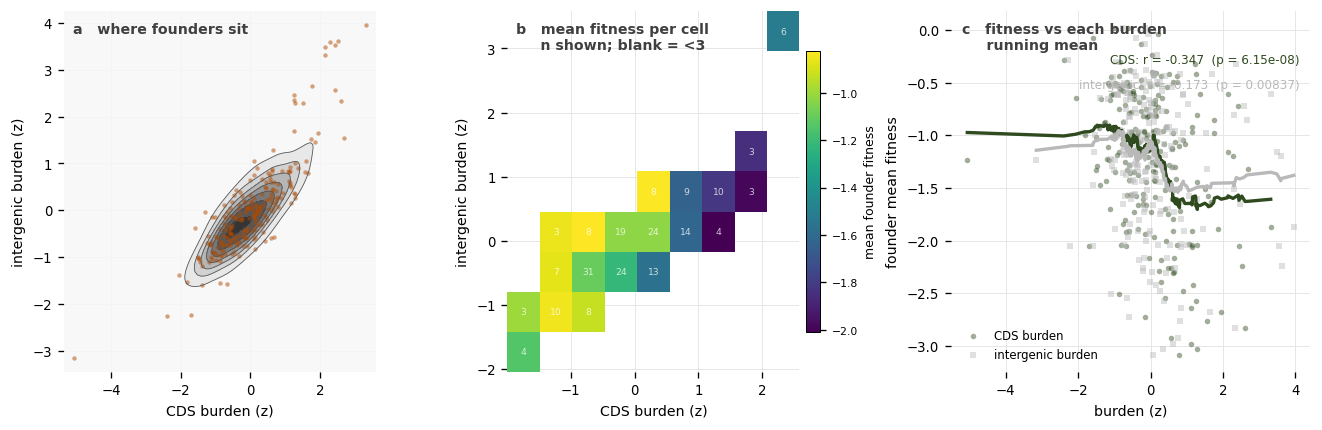

MARGINAL ASSOCIATION of each burden with founder mean fitness

  (no covariates at all -- NOT the model; kinship and everything else is what changes these)

  context        Pearson r           p   Spearman
  CDS               -0.347    6.15e-08     -0.329
  UTR               -0.267    3.96e-05     -0.248
  intron            -0.272    2.81e-05     -0.250
  TE                -0.175     0.00781     -0.162
  promoter          -0.237    0.000279     -0.210
  intergenic        -0.173     0.00837     -0.169

  founder fitness: mean -1.218, sd 0.656, range -3.090 to +0.022

  These marginal correlations are NOT the model's coefficients and should not be read as such:
  the model conditions on kinship, the SNP burden, assembly route, origin climate and the other
  five burdens. The raw-versus-adjusted contrast is section 9 of sv_burden_model.ipynb.


In [5]:

PAIR=("CDS","intergenic")
x=Z[PAIR[0]]; y_=Z[PAIR[1]]; fv2=FIT.loc[B.founder].to_numpy(float)
fig=plt.figure(figsize=(13.4,3.9))
gs=fig.add_gridspec(1,3,width_ratios=[1,1,1.15],wspace=0.40)
a=fig.add_subplot(gs[0,0]); style(a,axis="both")
try:
    kde=stats.gaussian_kde(np.vstack([x,y_]))
    xs=np.linspace(x.min()-.3,x.max()+.3,120); ys=np.linspace(y_.min()-.3,y_.max()+.3,120)
    XX,YY=np.meshgrid(xs,ys); ZZ=kde(np.vstack([XX.ravel(),YY.ravel()])).reshape(XX.shape)
    a.contourf(XX,YY,ZZ,levels=8,cmap="Greys",alpha=0.85)
    a.contour(XX,YY,ZZ,levels=8,colors="0.35",linewidths=0.5)
except Exception as e:
    print("KDE unavailable:",e)
a.scatter(x,y_,s=7,color="#B04A00",alpha=0.5,linewidth=0)
a.set_xlabel(f"{PAIR[0]} burden (z)",fontsize=8.5); a.set_ylabel(f"{PAIR[1]} burden (z)",fontsize=8.5)
a.annotate("a   where founders sit",xy=(0.03,0.97),xycoords="axes fraction",va="top",
           fontsize=8.5,color="0.25",fontweight="bold")
a=fig.add_subplot(gs[0,1]); style(a,axis="both")
NB=9; MINN=3
xe=np.linspace(np.percentile(x,1),np.percentile(x,99),NB+1)
ye=np.linspace(np.percentile(y_,1),np.percentile(y_,99),NB+1)
M=np.full((NB,NB),np.nan); Cn=np.zeros((NB,NB),int)
xi=np.clip(np.digitize(x,xe)-1,0,NB-1); yi=np.clip(np.digitize(y_,ye)-1,0,NB-1)
for i in range(NB):
    for j in range(NB):
        m=(xi==i)&(yi==j); Cn[j,i]=m.sum()
        if m.sum()>=MINN: M[j,i]=fv2[m].mean()
FN2=mpl.colors.Normalize(np.nanpercentile(M,5),np.nanpercentile(M,95))
im=a.pcolormesh(xe,ye,M,cmap="viridis",norm=FN2,shading="flat")
for i in range(NB):
    for j in range(NB):
        if Cn[j,i]>0 and not np.isnan(M[j,i]):
            a.annotate(f"{Cn[j,i]}",xy=((xe[i]+xe[i+1])/2,(ye[j]+ye[j+1])/2),ha="center",va="center",
                       fontsize=5.5,color="white",alpha=0.75)
cb=fig.colorbar(im,ax=a,pad=0.02,fraction=0.045); cb.set_label("mean founder fitness",fontsize=7.5)
cb.ax.tick_params(labelsize=6.5)
a.set_xlabel(f"{PAIR[0]} burden (z)",fontsize=8.5); a.set_ylabel(f"{PAIR[1]} burden (z)",fontsize=8.5)
a.annotate(f"b   mean fitness per cell\n     n shown; blank = <{MINN}",xy=(0.03,0.97),
           xycoords="axes fraction",va="top",fontsize=8.5,color="0.25",fontweight="bold")
a=fig.add_subplot(gs[0,2]); style(a,axis="both")
for c,mk in ((PAIR[0],"o"),(PAIR[1],"s")):
    v=Z[c]
    a.scatter(v,fv2,s=11,color=CC[c],alpha=0.45,linewidth=0,marker=mk,label=f"{c} burden")
    o=np.argsort(v); w=41
    if len(v)>w:
        run=pd.Series(fv2[o]).rolling(w,center=True,min_periods=15).mean()
        a.plot(v[o],run,color=CC[c],lw=2.0,zorder=3)
    r,pv=stats.pearsonr(v,fv2)
    a.annotate(f"{c}: r = {r:+.3f}  (p = {pv:.3g})",xy=(0.97,0.88-0.07*(c==PAIR[1])),
               xycoords="axes fraction",va="top",ha="right",fontsize=7.2,color=CC[c])
a.set_xlabel("burden (z)",fontsize=8.5); a.set_ylabel("founder mean fitness",fontsize=8.5)
a.legend(fontsize=7,loc="lower left")
a.annotate("c   fitness vs each burden\n     running mean",xy=(0.03,0.97),xycoords="axes fraction",
           va="top",fontsize=8.5,color="0.25",fontweight="bold")
save(fig,"diag_fitness_density",nb=True); plt.show()
print(f"MARGINAL ASSOCIATION of each burden with founder mean fitness\n")
print("  (no covariates at all -- NOT the model; kinship and everything else is what changes these)\n")
print(f"  {'context':12s} {'Pearson r':>11s} {'p':>11s} {'Spearman':>10s}")
for c in CTX:
    r,pv=stats.pearsonr(Z[c],fv2); sp=stats.spearmanr(Z[c],fv2).correlation
    print(f"  {c:12s} {r:+11.3f} {pv:11.3g} {sp:+10.3f}")
print(f"\n  founder fitness: mean {fv2.mean():+.3f}, sd {fv2.std(ddof=1):.3f}, "
      f"range {fv2.min():+.3f} to {fv2.max():+.3f}")
print("\n  These marginal correlations are NOT the model's coefficients and should not be read as such:")
print("  the model conditions on kinship, the SNP burden, assembly route, origin climate and the other")
print("  five burdens. The raw-versus-adjusted contrast is section 9 of sv_burden_model.ipynb.")


## 3 · The fitted per-garden effects

Each garden gets its own effect for each burden: `total = fixed_part + slope_blup`, where `fixed_part` is
the fixed effect plus its temperature term and `slope_blup` is that garden's random deviation.

**(a) Against garden temperature**, using the **totals**. This is the interaction, drawn: a sloped line
means the burden's effect depends on temperature.

⚠ **CDS and TE come out as perfect lines (r = ∓1.000), and that is not a result.** Their garden random
slope sits at the variance boundary — `sv_CDS` 5.1e-07, `sv_TE` 1.4e-10 — so every garden's deviation is
numerically zero and `total` reduces to `fixed_part`, which *is* a straight line in `bio1c`. The table
below prints the variance next to the spread of the deviations so this is checkable rather than asserted.
For the four burdens with real slope variance the scatter is genuine and their r (0.41–0.72) does mean
something.

**(b) Against each other**, using the **BLUP deviations only**. This is the part that matters, and it is
why the panel is not drawn from the totals: two totals both contain a straight line in `bio1c`, so
correlating them would mostly measure that shared line rather than anything about the gardens. The
deviations have the fixed part removed, so a correlation between them means two contexts genuinely move
together across gardens beyond what temperature explains.

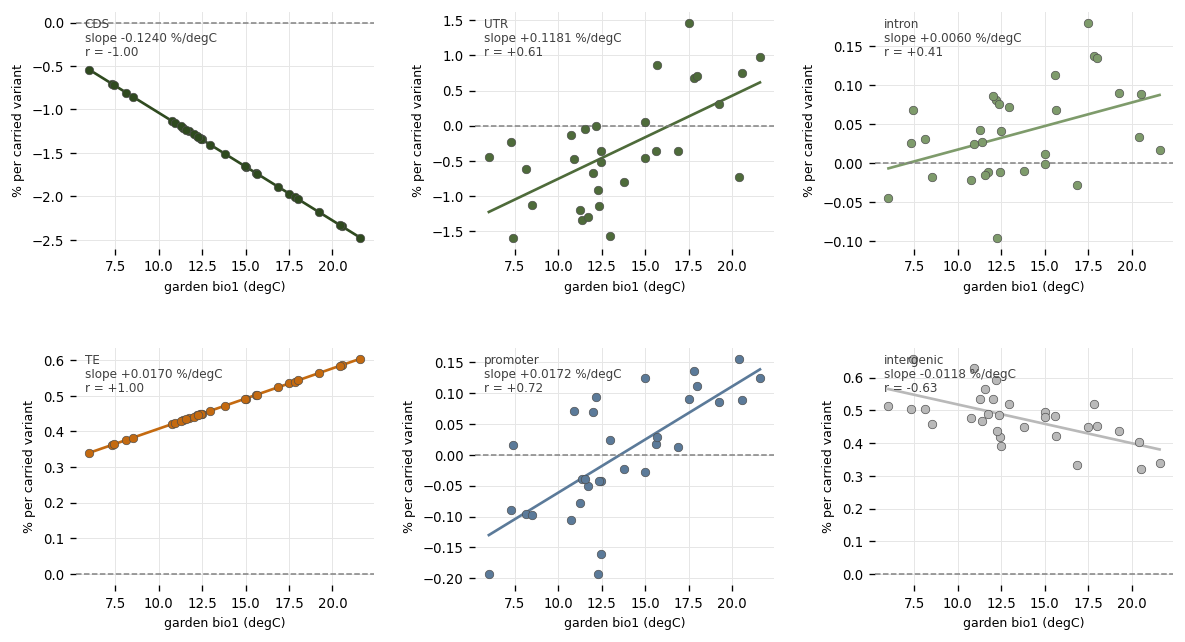

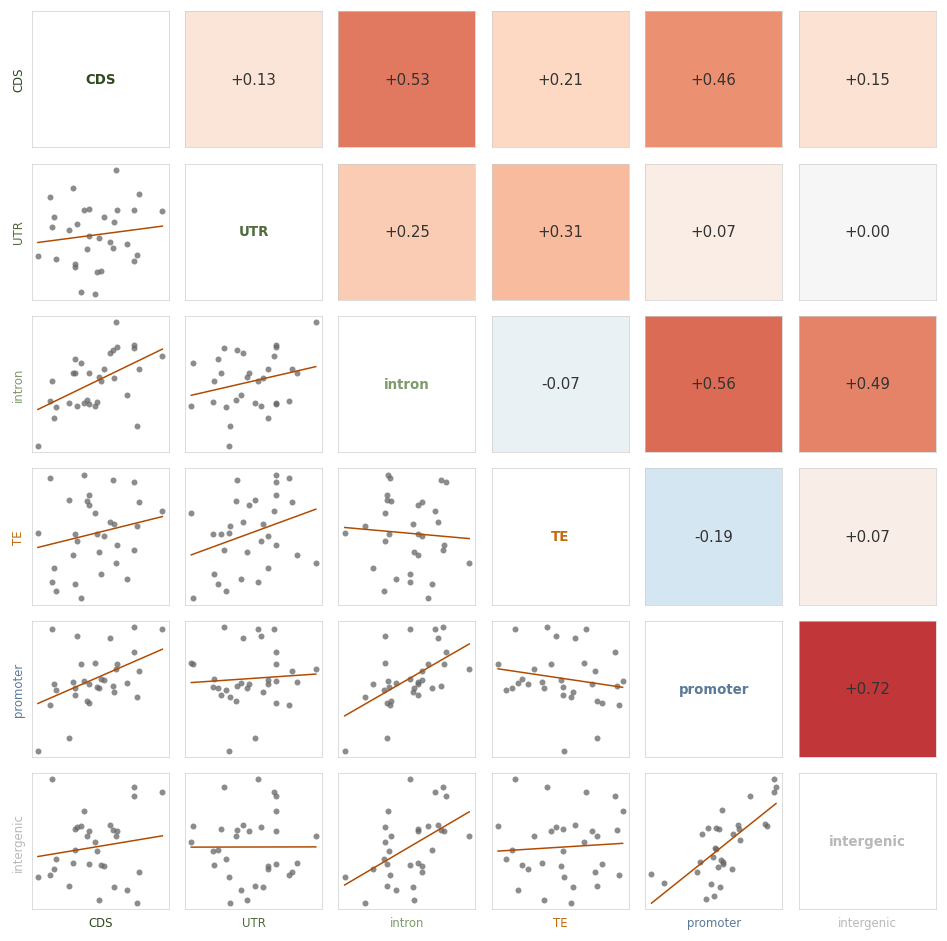

PER-GARDEN EFFECT vs GARDEN TEMPERATURE  (totals -- the interaction, drawn)

   context slope %/degC      r         p range across gardens
       CDS     -0.12400 -1.000 1.55e-129     -2.477 .. -0.543
       UTR     +0.11815 +0.613  0.000245     -1.594 .. +1.468
    intron     +0.00603 +0.411    0.0217     -0.096 .. +0.180
        TE     +0.01695 +1.000         0     +0.340 .. +0.604
  promoter     +0.01722 +0.722   4.6e-06     -0.193 .. +0.156
intergenic     -0.01184 -0.626  0.000167     +0.321 .. +0.658

  WHY TWO OF THESE ARE PERFECT LINES

    term            garden slope variance   SD of slope_blup   r(total, bio1)
    sv_CDS                      5.061e-07          3.753e-06          -1.0000
    sv_UTR                      3.870e-02          1.575e-01          +0.6132
    sv_intron                   5.320e-03          2.852e-02          +0.4107
    sv_TE                       1.401e-10          6.143e-10          +1.0000
    sv_promoter                 1.565e-02          7.082e-02

In [6]:

P=GD[GD.term.str.startswith("sv_")].copy()
P["ctx"]=P.term.str.replace("sv_","",regex=False)
TOT=P.pivot(index="garden",columns="ctx",values="total")
BLU=P.pivot(index="garden",columns="ctx",values="slope_blup")
BIO=P.drop_duplicates("garden").set_index("garden").bio1.reindex(TOT.index)
for c in CTX: TOT[c]=TOT[c]*PVv[f"sv_{c}"]; BLU[c]=BLU[c]*PVv[f"sv_{c}"]
fig,axs=plt.subplots(2,3,figsize=(11.8,6.2),gridspec_kw=dict(hspace=0.42,wspace=0.34))
for k,c in enumerate(CTX):
    a=axs[k//3,k%3]; style(a,axis="both")
    a.scatter(BIO,TOT[c],s=26,color=CC[c],edgecolor="0.3",linewidth=0.4,zorder=3)
    m,b0=np.polyfit(BIO,TOT[c],1); xs=np.array([BIO.min(),BIO.max()])
    a.plot(xs,m*xs+b0,color=CC[c],lw=1.6)
    a.axhline(0,color="0.5",lw=0.9,ls="--")
    r,pv=stats.pearsonr(BIO,TOT[c])
    a.annotate(f"{c}\nslope {m:+.4f} %/degC\nr = {r:+.2f}",xy=(0.03,0.97),xycoords="axes fraction",
               va="top",fontsize=7.2,color="0.25")
    a.set_xlabel("garden bio1 (degC)",fontsize=7.5)
    a.set_ylabel("% per carried variant",fontsize=7.5)
save(fig,"diag_garden_vs_temp",nb=True); plt.show()
n=len(CTX)
fig,axs=plt.subplots(n,n,figsize=(1.62*n,1.62*n),gridspec_kw=dict(hspace=0.12,wspace=0.12))
for i in range(n):
    for j in range(n):
        a=axs[i,j]; a.set_xticks([]); a.set_yticks([])
        for sp in a.spines.values(): sp.set_linewidth(0.4); sp.set_color("0.8")
        ci,cj=CTX[i],CTX[j]
        if i==j:
            a.annotate(ci,xy=(0.5,0.5),xycoords="axes fraction",ha="center",va="center",
                       fontsize=8,color=CC[ci],fontweight="bold")
        elif i>j:
            a.scatter(BLU[cj],BLU[ci],s=13,color="0.4",alpha=0.75,linewidth=0)
            if BLU[cj].std()>1e-12 and BLU[ci].std()>1e-12:
                m,b0=np.polyfit(BLU[cj],BLU[ci],1); xs=np.array([BLU[cj].min(),BLU[cj].max()])
                a.plot(xs,m*xs+b0,color="#B04A00",lw=0.9)
        else:
            if BLU[ci].std()<1e-12 or BLU[cj].std()<1e-12:
                a.annotate("n/a",xy=(0.5,0.5),xycoords="axes fraction",ha="center",va="center",
                           fontsize=7,color="0.6")
            else:
                r=np.corrcoef(BLU[ci],BLU[cj])[0,1]
                a.annotate(f"{r:+.2f}",xy=(0.5,0.5),xycoords="axes fraction",ha="center",va="center",
                           fontsize=9,color="0.2")
                a.set_facecolor(plt.get_cmap("RdBu_r")(0.5+r/2))
        if j==0: a.set_ylabel(ci,fontsize=7,color=CC[ci])
        if i==n-1: a.set_xlabel(cj,fontsize=7,color=CC[cj])
save(fig,"diag_garden_blup_pairs",nb=True); plt.show()
print("PER-GARDEN EFFECT vs GARDEN TEMPERATURE  (totals -- the interaction, drawn)\n")
print(pd.DataFrame([{"context":c,"slope %/degC":f"{np.polyfit(BIO,TOT[c],1)[0]:+.5f}",
                     "r":f"{stats.pearsonr(BIO,TOT[c])[0]:+.3f}",
                     "p":f"{stats.pearsonr(BIO,TOT[c])[1]:.3g}",
                     "range across gardens":f"{TOT[c].min():+.3f} .. {TOT[c].max():+.3f}"}
                    for c in CTX]).to_string(index=False))
VC=pd.read_csv(f"{PA}/varcomp_M2p_reml{SUF}.csv")
print("\n  WHY TWO OF THESE ARE PERFECT LINES\n")
print(f"    {'term':14s} {'garden slope variance':>22s} {'SD of slope_blup':>18s} {'r(total, bio1)':>16s}")
for c in CTX:
    t=f"sv_{c}"; q=VC[VC.var1==t].vcov
    vc=float(q.iloc[0]) if len(q) else float("nan")
    sg=P[P.term==t]
    print(f"    {t:14s} {vc:22.3e} {sg.slope_blup.std():18.3e}"
          f" {stats.pearsonr(sg.bio1,sg.total)[0]:+16.4f}")
print("\n  sv_CDS and sv_TE sit at the VARIANCE BOUNDARY: their garden slope variance is ~0, so every")
print("  garden gets slope_blup ~ 0 and `total` collapses to `fixed_part` = intercept + slope x bio1c,")
print("  a straight line by definition. Their r = +-1.000 is arithmetic, not evidence.")
print("  The other four have real slope variance, so their points scatter around the line and their")
print("  r (0.41 to 0.72) does carry information about how tightly the effect tracks temperature.")
print("\nPER-GARDEN BLUP DEVIATIONS, pairwise  (the fixed line removed)\n")
sd=BLU.std()
dead=[c for c in CTX if sd[c]<1e-9]
if dead: print(f"  at the variance boundary, no deviation to correlate: {', '.join(dead)}\n")
live=[c for c in CTX if c not in dead]
print(BLU[live].corr().round(3).to_string())
print("\n  A positive entry means two contexts are jointly stronger in the same gardens, beyond what")
print("  garden temperature already explains.")


## 4 · Does the number of events per context bias the coefficients?

The six contexts differ about fourfold in how many events they are built from — UTR 1,234 up to promoter
5,181. A burden assembled from fewer events is a **noisier measurement of the same founder property**, and
classical measurement error attenuates a coefficient toward zero in proportion to that noise. So the
better-measured contexts are flattered relative to the worse-measured ones, and the comparison *between*
contexts is biased even if each one individually is unbiased.

The test is direct: thin every context to the **same** expected number of events (~1,200, just under the
smallest), rebuild the burdens, refit, and repeat. Each replicate is an independent random draw of which
events to keep, so the spread across replicates is the sampling variation that thinning introduces.

If the pattern is an artefact of unequal counts, equalising should change it. If it is not, the
coefficients should keep their sign and their ordering — attenuated, because every context is now noisier
than before, but attenuated *together*.

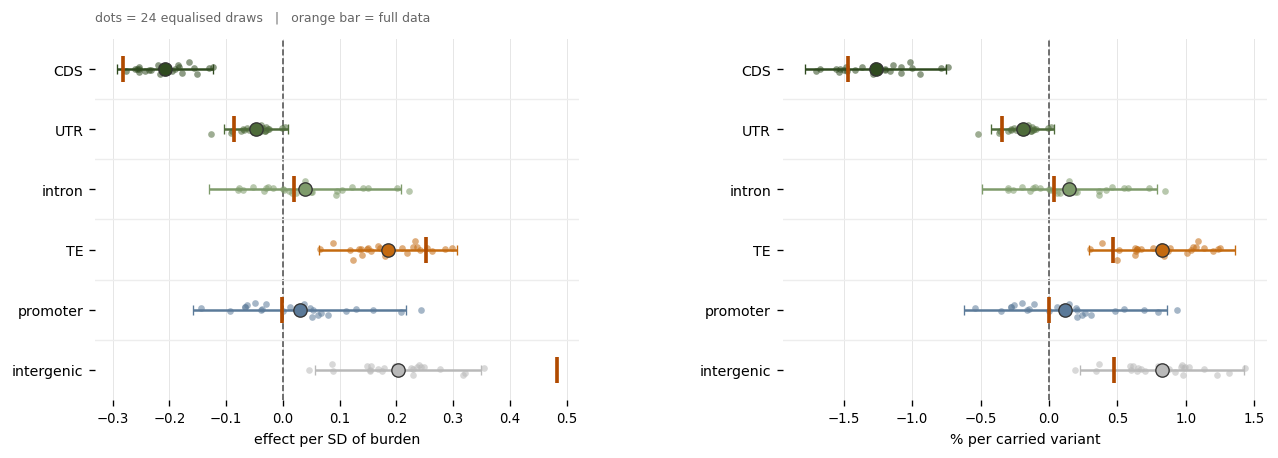

EVERY CONTEXT THINNED TO ~1,200 EVENTS -- 24 independent draws

  context       full per SD  equalised mean       sd            2.5-97.5%   draws keeping sign
  CDS               -0.2823         -0.2076   0.0430   [-0.267, -0.127]                 100%
  UTR               -0.0862         -0.0478   0.0289   [-0.106, +0.001]                  96%
  intron            +0.0200         +0.0391   0.0859   [-0.077, +0.211]                  67%
  TE                +0.2516         +0.1847   0.0620   [+0.079, +0.291]                 100%
  promoter          -0.0008         +0.0294   0.0955   [-0.115, +0.223]                  42%
  intergenic        +0.4838         +0.2032   0.0745   [+0.069, +0.335]                 100%

  per carried variant -- the scale the thinning does NOT change, since it divides by the
  realised event count of each draw:

  context        full data  equalised mean              2.5-97.5%  full inside?
  CDS              -1.4728         -1.2681   [-1.686, -0.768]           yes

In [7]:

import glob, re
EQ={c:[] for c in CTX}; EQV={c:[] for c in CTX}
for f in sorted(glob.glob(f"{PA}/coef_M2p_reml{SUF}_sub1200s*.csv")):
    sd_=re.search(r"_sub1200s(\d+)\.csv",f).group(1)
    co=pd.read_csv(f).set_index("term")
    sc=pd.read_csv(f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_all6_sub1200s{sd_}.csv").set_index("context")
    for c in CTX:
        EQ[c].append(co.loc[f"sv_{c}","estimate"])
        EQV[c].append(co.loc[f"sv_{c}","estimate"]*100/(sc.loc[c,"sd_rate"]*sc.loc[c,"med_called"]))
NR=len(EQ["CDS"])
fig,axs=plt.subplots(1,2,figsize=(12.6,3.9),gridspec_kw=dict(wspace=0.42))
for a,(D_,F_,lab) in zip(axs,
        ((EQ,{c:CO.loc[f"sv_{c}","estimate"] for c in CTX},"effect per SD of burden"),
         (EQV,{c:CO.loc[f"sv_{c}","estimate"]*PVv[f"sv_{c}"] for c in CTX},"% per carried variant"))):
    style(a); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,c in enumerate(CTX):
        v=np.array(D_[c])
        a.scatter(v,np.full(len(v),i)+np.random.default_rng(i).normal(0,0.055,len(v)),
                  s=16,color=CC[c],alpha=0.55,linewidth=0,zorder=2)
        a.errorbar(v.mean(),i,xerr=1.96*v.std(ddof=1),fmt="o",color=CC[c],mec="0.2",mew=0.8,
                   ms=8,capsize=3,zorder=3)
        a.plot([F_[c]],[i],marker="|",ms=16,mew=2.2,color="#B04A00",zorder=4)
        if i<len(CTX)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.set_yticks(range(len(CTX))); a.set_yticklabels(CTX,fontsize=8.5)
    a.set_ylim(len(CTX)-0.5,-0.5); a.set_xlabel(lab,fontsize=8.5)
axs[0].annotate(f"dots = {NR} equalised draws   |   orange bar = full data",
                xy=(0.0,1.05),xycoords="axes fraction",fontsize=7.5,color="0.4")
save(fig,"diag_equalised_counts",nb=True); plt.show()
print(f"EVERY CONTEXT THINNED TO ~1,200 EVENTS -- {NR} independent draws\n")
print(f"  {'context':12s} {'full per SD':>12s} {'equalised mean':>15s} {'sd':>8s} "
      f"{'2.5-97.5%':>20s} {'draws keeping sign':>20s}")
for c in CTX:
    v=np.array(EQ[c]); f0=CO.loc[f"sv_{c}","estimate"]
    keep=100*((v<0).mean() if f0<0 else (v>0).mean())
    print(f"  {c:12s} {f0:+12.4f} {v.mean():+15.4f} {v.std(ddof=1):8.4f}"
          f"   [{np.percentile(v,2.5):+.3f}, {np.percentile(v,97.5):+.3f}] {keep:19.0f}%")
print("\n  per carried variant -- the scale the thinning does NOT change, since it divides by the")
print("  realised event count of each draw:\n")
print(f"  {'context':12s} {'full data':>11s} {'equalised mean':>15s} {'2.5-97.5%':>22s} {'full inside?':>13s}")
for c in CTX:
    v=np.array(EQV[c]); f0=CO.loc[f"sv_{c}","estimate"]*PVv[f"sv_{c}"]
    lo,hi=np.percentile(v,[2.5,97.5])
    print(f"  {c:12s} {f0:+11.4f} {v.mean():+15.4f}   [{lo:+.3f}, {hi:+.3f}] {('yes' if lo<=f0<=hi else 'NO'):>13s}")
r_full=CO.loc["sv_intergenic","estimate"]/CO.loc["sv_TE","estimate"]
r_eq=np.array(EQ["intergenic"]).mean()/np.array(EQ["TE"]).mean()
print(f"\n  intergenic / TE, per SD:  full data {r_full:.2f}x   equalised {r_eq:.2f}x")


## 5 · The model has no `bio1c` main effect — does that matter?

The fitted formula interacts every burden with garden temperature (`sv_CDS:bio1c` and so on) and interacts
founder origin climate with it (`obio1c:bio1c`), but carries **no `bio1c` main effect**. That is a
deliberate consequence of the design — `(1 | garden)` gives each of the 31 gardens its own free intercept,
so any garden-level mean, a temperature trend among them included, is already absorbed by the random
intercepts and a `bio1c` fixed term would be redundant with them. It is still a violation of marginality
(interactions fitted without their lower-order term), and that is the kind of thing worth measuring
rather than asserting, so the whole model was refitted with `+ bio1c` added.

Below: the two fits side by side, and the largest absolute change in any coefficient.

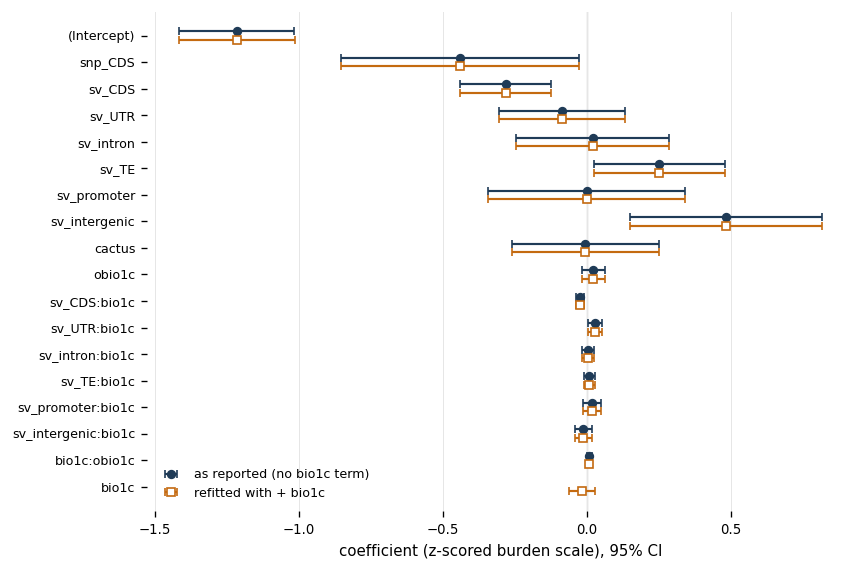

EFFECT OF ADDING THE bio1c MAIN EFFECT

  largest absolute change in any shared coefficient: 8.69e-06
  largest relative change:                           2.54e-03

  the bio1c term itself: -0.0174  (se 0.0229, p = 0.448)  -- indistinguishable from zero

  term                   as reported       + bio1c   p reported    p + bio1c
  (Intercept)              -1.216362     -1.216360     7.87e-33      1.7e-32
  snp_CDS                  -0.441581     -0.441589       0.0365       0.0365
  sv_CDS                   -0.282268     -0.282269     0.000488     0.000501
  sv_UTR                   -0.086204     -0.086203        0.442        0.442
  sv_intron                +0.019997     +0.019998        0.883        0.883
  sv_TE                    +0.251630     +0.251632       0.0301       0.0301
  sv_promoter              -0.000788     -0.000790        0.996        0.996
  sv_intergenic            +0.483794     +0.483803      0.00434      0.00435
  cactus                   -0.005794     -0.005798  

In [8]:

S2="_re0obio1cgarden_all6_refid_intall"
CA=pd.read_csv(f"{PA}/coef_M2p_reml_x_obio1cobio1cbio1c{S2}.csv")
CB=pd.read_csv(f"{PA}/coef_M2p_reml_x_obio1cobio1cbio1cbio1c{S2}.csv")
M=CA.merge(CB,on="term",how="outer",suffixes=("_a","_b"))
M["d"]=M.estimate_b-M.estimate_a
ORD=[t for t in M.term if t!="bio1c"]+["bio1c"]
M=M.set_index("term").loc[ORD].reset_index()
fig,ax=plt.subplots(figsize=(7.6,5.4)); style(ax,axis="x")
yy=np.arange(len(M))[::-1]
ax.axvline(0,color="0.75",lw=0.8,zorder=0)
for k,(col,lab,off,mk) in enumerate((("_a","as reported (no bio1c term)",+0.16,"o"),
                                     ("_b","refitted with + bio1c",-0.16,"s"))):
    e=M["estimate"+col].to_numpy(float); s=M["se"+col].to_numpy(float)
    c="#1F3B57" if k==0 else "#C46A10"
    ax.errorbar(e,yy+off,xerr=1.96*s,fmt=mk,ms=4.6,lw=1.3,capsize=2.2,color=c,label=lab,
                markerfacecolor="white" if k else c,zorder=3)
ax.set_yticks(yy); ax.set_yticklabels(M.term,fontsize=7.6)
ax.set_xlabel("coefficient (z-scored burden scale), 95% CI",fontsize=9)
ax.legend(fontsize=7.6,loc="lower left",frameon=False)
ax.set_ylim(-0.9,len(M)-0.1)
save(fig,"diag_bio1c_main",nb=True); plt.show()
d=M.d.abs()
print("EFFECT OF ADDING THE bio1c MAIN EFFECT\n")
print(f"  largest absolute change in any shared coefficient: {d.max():.2e}")
print(f"  largest relative change:                           "
      f"{(M.d.abs()/M.estimate_a.abs()).max():.2e}\n")
bb=M[M.term=="bio1c"].iloc[0]
print(f"  the bio1c term itself: {bb.estimate_b:+.4f}  (se {bb.se_b:.4f}, p = {bb.p_b:.3f})"
      "  -- indistinguishable from zero\n")
print(f"  {'term':20s} {'as reported':>13s} {'+ bio1c':>13s} {'p reported':>12s} {'p + bio1c':>12s}")
for _,r in M.iterrows():
    ea="     --      " if pd.isna(r.estimate_a) else f"{r.estimate_a:+13.6f}"
    pa="     --     " if pd.isna(r.p_a) else f"{r.p_a:12.3g}"
    print(f"  {r.term:20s} {ea} {r.estimate_b:+13.6f} {pa} {r.p_b:12.3g}")
print("\n  The 31 garden random intercepts already carry every garden-level mean, so a bio1c fixed")
print("  effect has nothing left to explain: it lands at zero and leaves the rest of the fit")
print("  numerically unchanged. The interactions are therefore not an artefact of the missing")
print("  main effect -- they are identified off within-garden contrasts, which the intercepts")
print("  do not touch. Keeping the term out costs nothing and keeps the reported model as it is.")


## 6 · Reading it

**On the distributions (§1).** The burdens are not normal, and the model does not require them to be —
linear mixed models assume normality of the *residuals*, not of the covariates. A skewed covariate is
fine; what it costs is leverage concentration, since the founders in the tail carry disproportionate
weight in that coefficient. That is exactly what §10–§11 of `sv_burden_model.ipynb` test by refitting
without them, and the estimate does not move.

**On the pairwise structure (§2).** Fitness colour runs across the cloud rather than along it: founders
high and low in fitness are not separated in burden space, which is what you would expect when the
burden effects are small relative to the between-founder spread. The two technology symbols overlap
throughout, so neither panel occupies its own region of the space.

The correlations are high but the relationships are close to linear —
Spearman and Pearson agree closely across all 15 pairs. If they had diverged, the additive linear model
would have been the wrong functional form and no re-parameterisation would have rescued it. They don't,
so the issue with these burdens is collinearity, not mis-specification. Those are different problems with
different fixes.

**On the per-garden effects (§3).** The vs-temperature panels are the interactions drawn out. For
**CDS and TE** the correlation is exactly ∓1 because their garden random slope is at the variance
boundary: with no deviation left, `total` is the fixed line and nothing else. Reading those two panels as
"the effect tracks temperature beautifully" would be reading the model's own parameterisation back out of
itself. For the other four the slope variance is real and the scatter is informative.

In all six panels it is the **slope** that carries the interaction, not the correlation.

The pairwise BLUP panel is the one that can surprise. Contexts whose garden deviations correlate are
jointly stronger in the same gardens for a reason temperature does not capture — which is a hint about an
unmodelled garden-level variable, not about the contexts themselves.

⚠ Burdens whose garden random slope sat at the variance boundary have no deviation to correlate, and are
marked `n/a` rather than being shown as a spurious zero.

**On the equalised counts (§4).** The contexts are measured on wildly different numbers of events, and
thinning them all to a common size does not flip any sign: CDS stays negative in every draw, TE and
intergenic stay positive in every draw. What it does change is the *ranking* among the positives —
intergenic's edge over TE shrinks from 1.9× to 1.1×, so part of what looked like intergenic being the
strongest positive was intergenic being measured on four times as many events. The signs are robust to
event count; the fine ordering of the non-coding positives is not, and should not be argued from.

**On the missing main effect (§5).** It changes nothing — no coefficient moves beyond the sixth decimal,
and `bio1c` itself lands at zero. The garden random intercepts already absorb every garden-level mean, so
the interactions are identified off within-garden contrasts and cannot be an artefact of the absent
lower-order term.

## As run

Sections 1–3 are read from the reported fit — `coef_M2p_reml`, `garden_M2p_reml` with suffix
`_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall` — and from `founder_burden_event.csv`, with
nothing refitted. Sections 4 and 5 are refits, each under its own output suffix so neither can overwrite
the reported one: §4 rebuilds the burden table under `SUBSAMPLE_N` / `SUBSAMPLE_SEED` and refits per draw,
§5 adds `+ bio1c` to `EXTRA_FIXED` (suffix `_x_obio1cobio1cbio1cbio1c…`) and is otherwise the identical
specification.

- **Burdens** are `carried / called` per context, z-scored across the 231 founders, exactly as the model
  receives them. The raw carried counts are shown alongside because the z-score hides the scale.
- **Per-garden effects** are `total = fixed_part + slope_blup` from the R output, converted to % per
  carried variant with the arm's `pooled_rate_scale`.
- **Why the pairwise panel uses BLUPs and the temperature panel uses totals** is in §3: `fixed_part` is a
  deterministic line in `bio1c`, so a total-vs-total correlation is largely that line appearing twice.
- Shapiro–Wilk at n = 231 is sensitive — it will reject mild departures. The skew and kurtosis values are
  the more useful summary; the test is reported for completeness, not as a gate.